<a href="https://colab.research.google.com/github/bagas43325205-sudo/Computer-Vision/blob/main/Jobsheet_3_Teknik_Regresi_Gambar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Bagas Idden Listiyanto / 4.33.25.2.05**

### **Praktikum D1 – Regresi dari Citra Sintetis (Prediksi Radius Lingkaran)**

### **1) Setup & Generator Dataset**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras import layers, models

# Generator 1 sample
def make_sample(img_size=64, min_r=5, max_r=20):
  r = np.random.randint(min_r, max_r + 1)               # radius acak
  img = np.zeros((img_size, img_size), dtype=np.uint8)
  cx = np.random.randint(r, img_size - r)               # center-x
  cy = np.random.randint(r, img_size - r)               # center-y
  cv2.circle(img, (cx, cy), r, 255, -1)                 # lingkaran putih terisi
  img = (img / 255.0).astype(np.float32)
  # 3-channel biar kompatibel CNN
  img3 = np.stack([img, img, img], axis=-1)
  return img3, float(r), (cx, cy)

### **2) "Tebak Apa?" - Tampilkan Contoh Gambar TANPA Label**

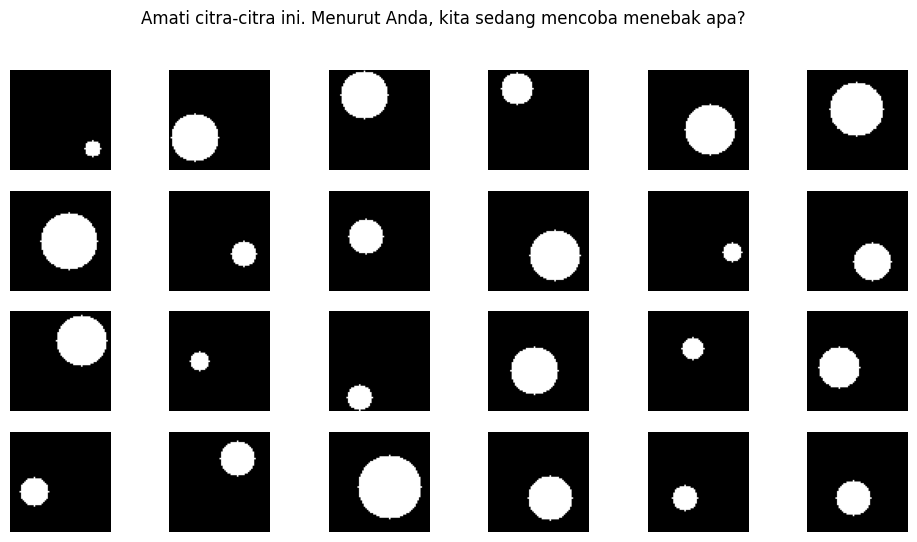

In [ ]:
# Buat 24 contoh untuk visualisasi
N_show = 24
samples = [make_sample () for _ in range(N_show)]
imgs = [s[0] for s in samples]
rads = [s[1] for s in samples]
centers = [s[2] for s in samples]
# Grid gambar tanpa label:
cols = 6
rows = N_show // cols
plt.figure(figsize=(12, 6))
for i in range(N_show):
  plt.subplot(rows, cols, i + 1)
  plt.imshow(imgs[i].squeeze(), cmap='gray')
  plt.axis('off')
plt.suptitle("Amati citra-citra ini. Menurut Anda, kita sedang mencoba menebak apa?")
plt.tight_layout
plt.show()

### **3) Buka Jawaban — Target yang Ingin Diprediksi**

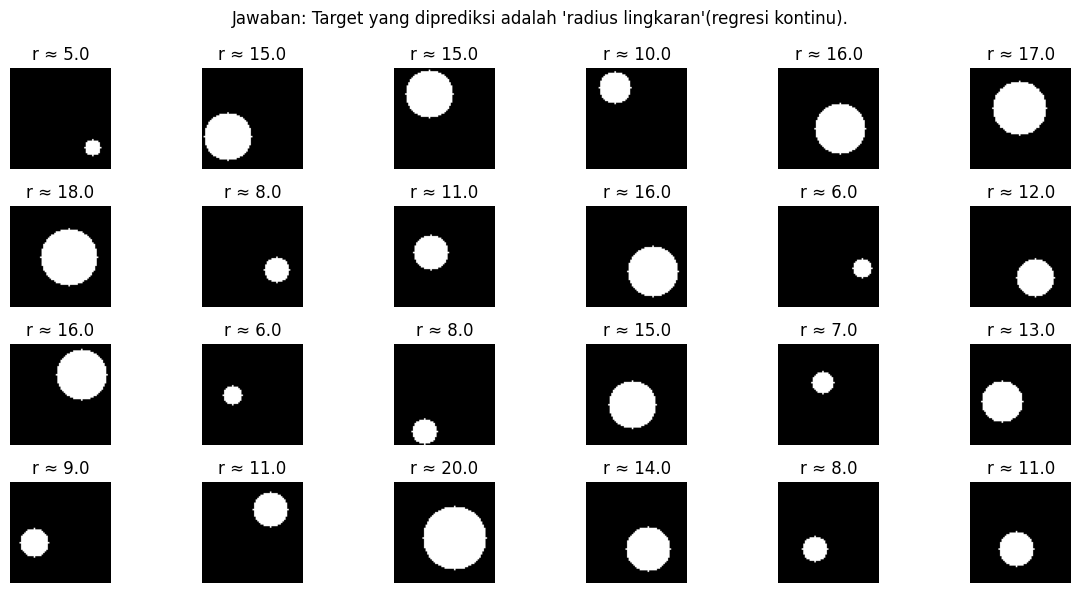

In [ ]:
# Tampilkan kembali, sekarang tampilkan radius (label) di judul tiap subplot
plt.figure(figsize = (12, 6))
for i in range(N_show):
  plt.subplot(rows, cols, i + 1)
  plt.imshow(imgs[i].squeeze(), cmap = 'gray')
  plt.title(f"r ≈ {rads[i]}")
  plt.axis('off')
plt.suptitle("Jawaban: Target yang diprediksi adalah 'radius lingkaran'(regresi kontinu).")
plt.tight_layout()
plt.show()

### **4) (Opsional) Latih CNN Kecil untuk Memprediksi Radius**

In [ ]:
# Siapkan dataset lebih besar untuk training
N = 3000
X, y, C = zip(*[make_sample() for _ in range(N)])
X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

# Model CNN sederhana
model = models.Sequential([
  layers.Input((64, 64, 3)),
  layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(),
  layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(),
  layers.Conv2D(128, 3, activation='relu'),
layers.GlobalAveragePooling2D(),
  layers.Dense(64, activation='relu'),
  layers.Dense(1) # output regresi
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
history = model.fit(Xtr, ytr, validation_data=(Xte, yte), epochs=12,
                    batch_size=64, verbose=0)

# Evaluasi
y_pred = model.predict(Xte).ravel()
mae = mean_absolute_error(yte, y_pred)
rmse = float(np.sqrt(np.mean((yte - y_pred)**2)))
r2 = r2_score(yte, y_pred)
print(f"MAE={mae:.3f} | RMSE={rmse:.3f} | R²={r2:.3f}")

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step
MAE=0.946 | RMSE=1.145 | R²=0.942


### **Plot history & True vs Predicted:**

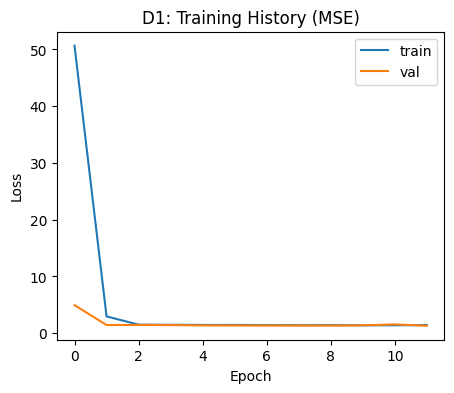

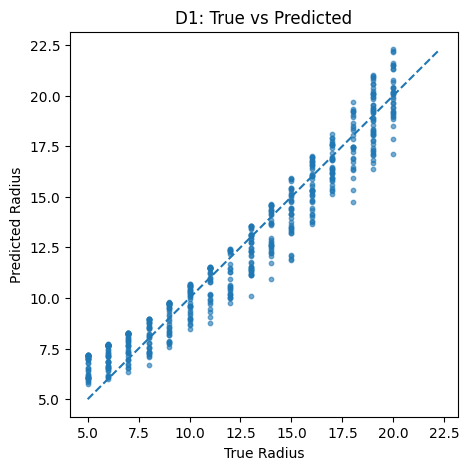

In [ ]:
# Plot loss
plt.figure(figsize=(5, 4))
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title("D1: Training History (MSE)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()

# Scatter True vs Pred
plt.figure(figsize=(5, 5))
plt.scatter(yte, y_pred, s=10, alpha=0.6)
lims = [min(yte.min(), y_pred.min()), max(yte.max(), y_pred.max())]
plt.plot(lims, lims, '--')
plt.xlabel("True Radius"); plt.ylabel("Predicted Radius")
plt.title("D1: True vs Predicted")
plt.show()

### **5) Tantangan Mini (Opsional untuk Mahasiswa)**

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras import layers, models

# ==========================================
# 1. GENERATOR DATASET DENGAN FUNGSI NOISE & MULTI-OUTPUT
# ==========================================
def make_sample_advanced(img_size=64, min_r=8, max_r=28, noise_type=None):
    r = np.random.randint(min_r, max_r + 1)
    img = np.zeros((img_size, img_size), dtype=np.uint8)
    cx = np.random.randint(r, img_size - r)
    cy = np.random.randint(r, img_size - r)
    cv2.circle(img, (cx, cy), r, (255,), -1)

    # Penambahan Noise
    if noise_type == 'gaussian':
        noise = np.random.normal(0, 25, (img_size, img_size)).astype(np.float32)
        img = np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    elif noise_type == 'blur':
        img = cv2.GaussianBlur(img, (7, 7), 0)

    img = (img / 255.0).astype(np.float32)
    img3 = np.stack([img, img, img], axis=-1)

    # Return citra, radius, dan koordinat pusat (cx, cy)
    return img3, float(r), float(cx), float(cy)

# ==========================================
# 2. TANTANGAN 1 & 2: PERUBAHAN RENTANG RADIUS (8-28) & NOISE
# ==========================================
N = 3000
# Membuat dataset dengan rentang radius 8-28 dan Gaussian Noise
data_challenge = [make_sample_advanced(min_r=8, max_r=28, noise_type='gaussian') for _ in range(N)]

X_c = np.array([s[0] for s in data_challenge], dtype=np.float32)
y_c = np.array([s[1] for s in data_challenge], dtype=np.float32) # Target: Radius

Xtr_c, Xte_c, ytr_c, yte_c = train_test_split(X_c, y_c, test_size=0.2, random_state=42)

model_single = models.Sequential([
    layers.Input((64, 64, 3)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1) # Output tunggal: Radius
])

model_single.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_single.fit(Xtr_c, ytr_c, validation_data=(Xte_c, yte_c), epochs=12, batch_size=64, verbose=0)

# Evaluasi Single Output
pred_c = model_single.predict(Xte_c, verbose=0).ravel()
mae_c = mean_absolute_error(yte_c, pred_c)
rmse_c = float(np.sqrt(np.mean((yte_c - pred_c) ** 2)))
r2_c = r2_score(yte_c, pred_c)

print("=== HASIL TANTANGAN 1 & 2 (Rentang 8-28 + Gaussian Noise) ===")
print(f"MAE  : {mae_c:.3f}")
print(f"RMSE : {rmse_c:.3f}")
print(f"R²   : {r2_c:.3f}\n")

# ==========================================
# 3. TANTANGAN 3: MULTI-OUTPUT REGRESSION [r, cx, cy]
# ==========================================
# Dataset multi-output
data_multi = [make_sample_advanced(min_r=5, max_r=20, noise_type=None) for _ in range(N)]

X_m = np.array([s[0] for s in data_multi], dtype=np.float32)
y_m = np.array([[s[1], s[2], s[3]] for s in data_multi], dtype=np.float32) # Target: [r, cx, cy]

Xtr_m, Xte_m, ytr_m, yte_m = train_test_split(X_m, y_m, test_size=0.2, random_state=42)

model_multi = models.Sequential([
    layers.Input((64, 64, 3)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(3) # Output 3 neuron: [r, cx, cy]
])

model_multi.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_multi.fit(Xtr_m, ytr_m, validation_data=(Xte_m, yte_m), epochs=15, batch_size=64, verbose=0)

# Evaluasi Multi Output
pred_m = model_multi.predict(Xte_m, verbose=0)

mae_r = mean_absolute_error(yte_m[:, 0], pred_m[:, 0])
mae_cx = mean_absolute_error(yte_m[:, 1], pred_m[:, 1])
mae_cy = mean_absolute_error(yte_m[:, 2], pred_m[:, 2])

print("=== HASIL TANTANGAN 3 (Multi-Output [r, cx, cy]) ===")
print(f"MAE Radius (r)     : {mae_r:.3f}")
print(f"MAE Center-X (cx)  : {mae_cx:.3f}")
print(f"MAE Center-Y (cy)  : {mae_cy:.3f}")
print(f"Mean MAE Keseluruhan: {np.mean([mae_r, mae_cx, mae_cy]):.3f}")

=== HASIL TANTANGAN 1 & 2 (Rentang 8-28 + Gaussian Noise) ===
MAE  : 0.764
RMSE : 0.948
R²   : 0.976

=== HASIL TANTANGAN 3 (Multi-Output [r, cx, cy]) ===
MAE Radius (r)     : 1.085
MAE Center-X (cx)  : 4.321
MAE Center-Y (cy)  : 4.359
Mean MAE Keseluruhan: 3.255


### **Praktikum D2 – Menebak Umur Manusia dari Foto Wajah (UTKFace)**

### **Langkah 1 — Membuat Akun Kaggle dan Mengunduh kaggle.json**

Agar dapat mengakses dataset publik Kaggle, mahasiswa perlu membuat akun terlebih dahulu.
Ikuti langkah berikut:
1.	Buka situs https://www.kaggle.com
2.	Daftar menggunakan email Google atau GitHub.
3.	Setelah login, klik profil di kanan atas → pilih “Account”.
4.	Gulir ke bawah ke bagian API → klik “Create New API Token”.
5.	File bernama kaggle.json akan otomatis terunduh ke komputer Anda.
File ini berisi API key pribadi agar Colab bisa mengakses dataset Kaggle Anda.
Simpan file kaggle.json dengan baik (jangan dibagikan ke orang lain).


In [ ]:
# Jalankan ini di awal notebook
from google.colab import files
files.upload() # pilih file kaggle.json dari komputer Anda

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"bagasiddenti","key":"2595fb3b20d8569c953ea6ef39252ff9"}'}

Setelah diunggah, jalankan sel berikut untuk menyiapkan koneksi Kaggle:

In [ ]:
import os, shutil
if os.path.exists("kaggle.json"):
  os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
  shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
  os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
  !pip -q install kaggle
  print("✅ Kaggle API siap digunakan.")
else:
  print("! kaggle.json belum ditemukan. Upload terlebih dahulu.")

✅ Kaggle API siap digunakan.


# **Langkah 3 - Mengunduh Dataset UTKFace dari Kaggle**

In [ ]:
# Unduh dataset UTKFace (sekali saja) dengan perintah yang benar
!kaggle datasets download -d jangedoo/utkface-new -p /content -q
!unzip -q /content/utkface-new.zip -d /content/utk
print("✅ Dataset UTKFace berhasil diekstrak.")

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
✅ Dataset UTKFace berhasil diekstrak.


# **Langkah 4 - Menampilkan Contoh Gambar Dataset**

Total gambar ditemukan: 23708


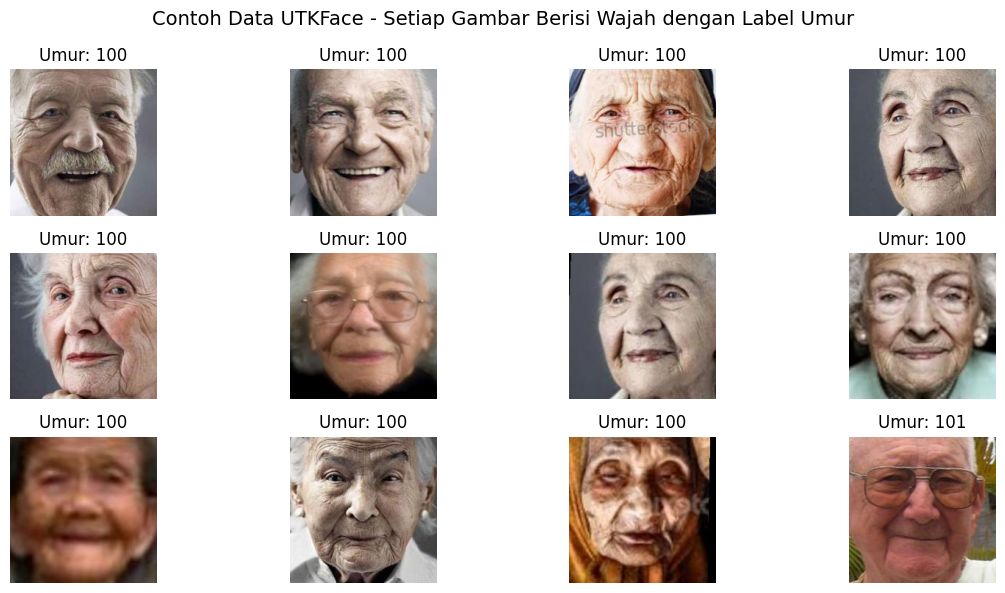

In [ ]:
from os.path import basename
from IPython.core.display import Image
import matplotlib.pyplot as plt
import os, glob
from PIL import Image

# Ambil 12 gambar acak dari dataset
files = glob.glob("/content/utk/UTKFace/*.jpg")
files = sorted(files)
print(f"Total gambar ditemukan: {len(files)}")
plt.figure(figsize=(12, 6))
for i, file in enumerate(files[:12]):
  # Ambil umur dari nama file
  age = int(os.path.basename(file).split("_")[0])
  img = Image.open(file)
  plt.subplot(3, 4, i + 1)
  plt.imshow(img)
  plt.title(f"Umur: {age}")
  plt.axis("off")
plt.suptitle("Contoh Data UTKFace - Setiap Gambar Berisi Wajah dengan Label Umur", fontsize=14)
plt.tight_layout()
plt.show()

# **Langkah 5 - Siapkan Dataset untuk Model**

In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split

def parse_age_from_name(fp):
  return int(os.path.basename(fp).split('_')[0])

ages = np.array([parse_age_from_name(f) for f in files], dtype=np.float32)
train_files, test_files, y_train, y_test = train_test_split(
files, ages, test_size=0.2, random_state=42
)

IMG_SIZE = 160
def load_img(fp, label):
  img = tf.io.read_file(fp)
  img = tf.image.decode_jpeg(img, channels=3)
  img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
  return img / 255.0, label

train_ds = tf.data.Dataset.from_tensor_slices((train_files,
y_train)).map(load_img).batch(64)
test_ds = tf.data.Dataset.from_tensor_slices((test_files,
y_test)).map(load_img).batch(64)

print("✅ Dataset siap dilatih.")


✅ Dataset siap dilatih.


# **Langkah 6 - Membangun Model dengan Transfer Learning**

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Gunakan GPU jika tersedia
print("Hardware:", "GPU" if tf.config.list_physical_devices('GPU') else "CPU")

# Buat arsitektur model
base_model = tf.keras.applications.MobileNetV2(
  include_top=False,
  input_shape=(IMG_SIZE, IMG_SIZE, 3),
  weights='imagenet'
)
base_model.trainable = False # tahap awal: freeze backbone

# Tambahkan head regresi
inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs * 255.0)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
x = layers.Dense(128, activation='relu')(x)
outputs = layers.Dense(1)(x) # output tunggal: umur
model = tf.keras.Model(inputs, outputs)

# Kompilasi model
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='mse', metrics=['mae'])

model.summary()

Hardware: GPU
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_2 (Multiply)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# **Langkah 7 — Melatih Model (Tahap 1 – Frozen)**

Epoch 1/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 46s 107ms/step - loss: 215.3959 - mae: 10.9273 - val_loss: 159.3197 - val_mae: 9.6530 - learning_rate: 0.0010
Epoch 2/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - loss: 149.7307 - mae: 9.1161 - val_loss: 144.5773 - val_mae: 9.0551 - learning_rate: 0.0010
Epoch 3/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 21s 41ms/step - loss: 140.1933 - mae: 8.7657 - val_loss: 138.2701 - val_mae: 8.7509 - learning_rate: 0.0010
Epoch 4/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - loss: 135.1981 - mae: 8.6119 - val_loss: 133.7912 - val_mae: 8.4733 - learning_rate: 0.0010
Epoch 5/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 12s 40ms/step - loss: 132.6928 - mae: 8.5069 - val_loss: 133.8925 - val_mae: 8.5706 - learning_rate: 0.0010
Epoch 6/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 16s 52ms/step - loss: 131.4612 - mae: 8.4567 - val_loss: 132.2455 - val_mae: 8.5109 - learning_rate: 0.0010
Epoch 7/10
297/297 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - loss: 127.2348 - mae: 8.2838 - val_loss: 130.4801 - va

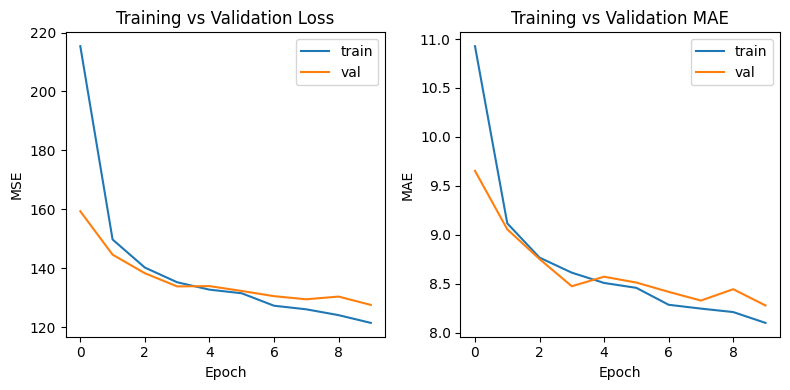

In [ ]:
#Callback untuk pelatihan yang lebih stabil
cb = [
  tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True,
monitor='val_loss'),
  tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, min_lr=1e-5, monitor='val_loss')
  ]

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10,
    callbacks=cb,
    verbose=1
)

# Visualisasi perubahan loss dan MAE selama pelatihan:
plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Training vs Validation Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['mae'], label='train')
plt.plot(history.history['val_mae'], label='val')
plt.xlabel('Epoch'); plt.ylabel('MAE')
plt.title('Training vs Validation MAE')
plt.legend()
plt.tight_layout()
plt.show()


# **Langkah 8 - Fine tunning Backbone (Tahap 2)**

Epoch 1/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 48s 99ms/step - loss: 147.0733 - mae: 8.9366 - val_loss: 139.0015 - val_mae: 8.9472 - learning_rate: 1.0000e-04
Epoch 2/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - loss: 71.9296 - mae: 6.3682 - val_loss: 115.0128 - val_mae: 8.2267 - learning_rate: 1.0000e-04
Epoch 3/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - loss: 49.6606 - mae: 5.3392 - val_loss: 106.6987 - val_mae: 7.7820 - learning_rate: 1.0000e-04
Epoch 4/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - loss: 36.2726 - mae: 4.5927 - val_loss: 102.1322 - val_mae: 7.5100 - learning_rate: 1.0000e-04
Epoch 5/5
297/297 ━━━━━━━━━━━━━━━━━━━━ 14s 48ms/step - loss: 29.8718 - mae: 4.1716 - val_loss: 107.1347 - val_mae: 7.5266 - learning_rate: 1.0000e-04


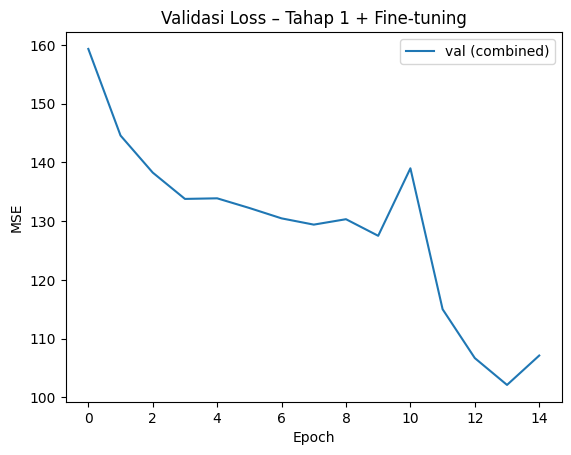

In [ ]:
# Aktifkan kembali sebagian layer terakhir untuk fine-tuning
base_model.trainable = True
for layer in base_model.layers[:-30]:
  layer.trainable = False # beku sebagian besar layer

# Recompile dengan learning rate lebih kecil
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
              loss='mse', metrics=['mae'])
history_ft = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5,
    callbacks=cb,
    verbose=1
)

# Visualisasi gabungan training dan fine-tuning:
plt.plot(history.history['val_loss'] + history_ft.history['val_loss'],
label='val (combined)')
plt.title("Validasi Loss – Tahap 1 + Fine-tuning")
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.legend(); plt.show()


# **Langkah 9 — Evaluasi Akhir (MAE, RMSE, R²)**

MAE = 7.51 tahun
RMSE = 10.11 tahun
R²	= 0.743


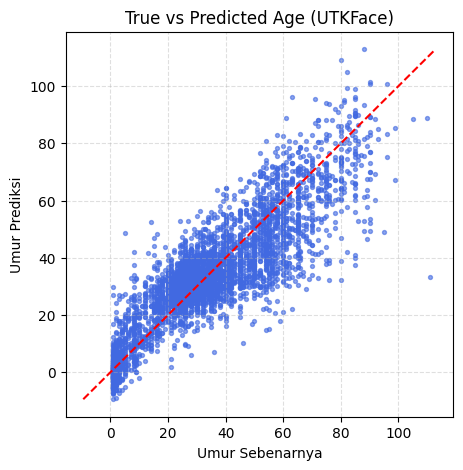

In [ ]:
from math import sqrt

y_pred = np.concatenate([model.predict(batch[0], verbose=0).ravel() for
                         batch in test_ds])
mae = mean_absolute_error(y_test, y_pred)
rmse = sqrt(np.mean((y_test - y_pred)**2))
r2 = r2_score(y_test, y_pred)

print(f"MAE = {mae:.2f} tahun")
print(f"RMSE = {rmse:.2f} tahun")
print(f"R²	= {r2:.3f}")

# Plot “umur sebenarnya vs umur prediksi”:
plt.figure(figsize=(5,5))
plt.scatter(y_test, y_pred, s=8, alpha=0.6, color='royalblue')
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='red')
plt.xlabel("Umur Sebenarnya")
plt.ylabel("Umur Prediksi")
plt.title("True vs Predicted Age (UTKFace)")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

# **Langkah 10 — Melihat Contoh Prediksi Nyata**

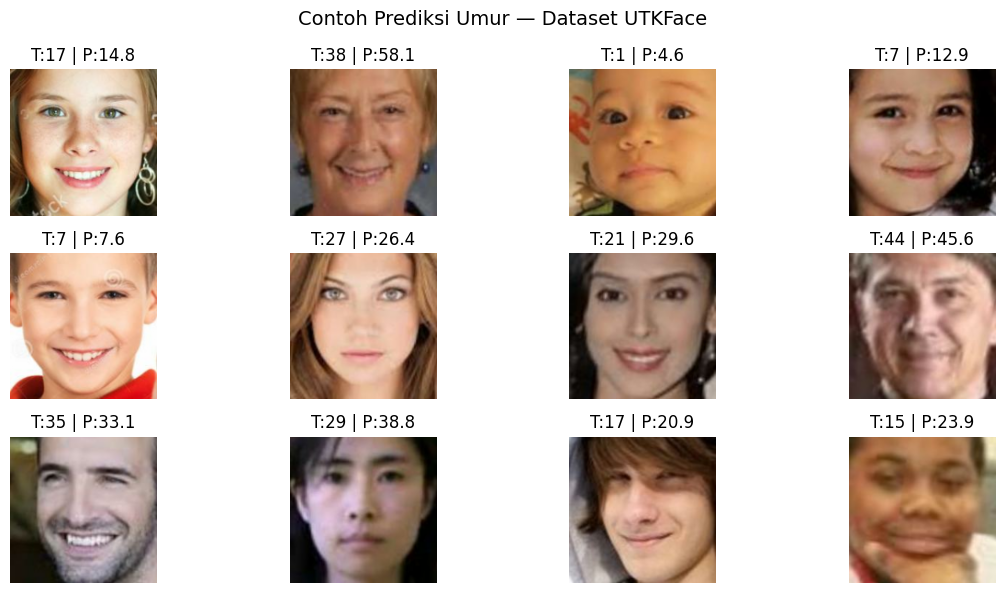

In [ ]:
import random
sample_paths = random.sample(test_files, 12)

plt.figure(figsize=(12,6))
for i, path in enumerate(sample_paths):
  img = tf.io.read_file(path)
  img = tf.image.decode_jpeg(img, channels=3)
  img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))/255.0
  true_age = int(os.path.basename(path).split('_')[0])
  pred_age = model.predict(tf.expand_dims(img, 0), verbose=0).ravel()[0]
  plt.subplot(3,4,i+1)
  plt.imshow(img.numpy())
  plt.title(f"T:{true_age} | P:{pred_age:.1f}")
  plt.axis('off')
plt.suptitle("Contoh Prediksi Umur — Dataset UTKFace", fontsize=14)
plt.tight_layout()
plt.show()


# **Tantangan Mini (Opsional)**

=== MAE PER KELOMPOK UMUR ===
Age_Group
0-10      5.139661
11-20     8.130417
21-30     5.665560
31-40     5.916728
41-50     8.935264
51-60    11.372435
61-70    12.971775
71+      14.463453
Name: MAE, dtype: float32


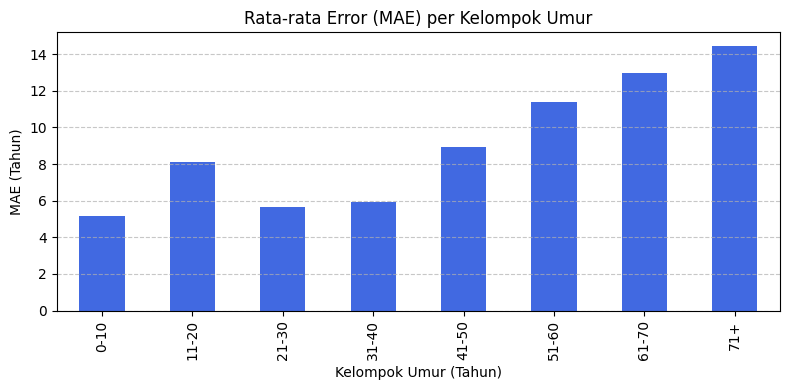

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras import layers, models

# ==========================================
# 1. DATA AUGMENTATION EKSTRA (Kontras, Brightness, Zoom)
# ==========================================
data_augmentation = tf.keras.Sequential([
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
    layers.RandomZoom(0.2),
    layers.RandomFlip("horizontal")
])

def load_img_augmented(fp, label):
    img = tf.io.read_file(fp)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (160, 160)) / 255.0
    img = data_augmentation(img)
    return img, label

# Dataset dengan Augmentasi
train_ds_aug = tf.data.Dataset.from_tensor_slices((train_files, y_train))\
    .map(load_img_augmented, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(64).prefetch(tf.data.AUTOTUNE)

# ==========================================
# 2. LEARNING RATE SCHEDULE & OPTIMIZER COSTUM
# ==========================================
initial_learning_rate = 1e-3
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=initial_learning_rate,
    decay_steps=1000
)

custom_optimizer = tf.keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=1e-4)

# Kompilasi ulang model dengan optimizer & schedule baru
model.compile(optimizer=custom_optimizer, loss='mse', metrics=['mae'])

# ==========================================
# 3. EVALUASI PER KELOMPOK UMUR (Group Error Analysis)
# ==========================================
y_pred_d2 = np.concatenate([model.predict(batch[0], verbose=0).ravel() for batch in test_ds])

# Buat DataFrame untuk mempermudah grouping
df_eval = pd.DataFrame({
    'True_Age': y_test,
    'Pred_Age': y_pred_d2,
    'MAE': np.abs(y_test - y_pred_d2)
})

# Definisikan kelompok umur (bins)
bins = [0, 10, 20, 30, 40, 50, 60, 70, 100]
labels = ['0-10', '11-20', '21-30', '31-40', '41-50', '51-60', '61-70', '71+']
df_eval['Age_Group'] = pd.cut(df_eval['True_Age'], bins=bins, labels=labels)

# Hitung MAE per kelompok umur (Menambahkan observed=False untuk mengatasi FutureWarning)
group_mae = df_eval.groupby('Age_Group', observed=False)['MAE'].mean()

print("=== MAE PER KELOMPOK UMUR ===")
print(group_mae)

# Visualisasi Group Error
plt.figure(figsize=(8, 4))
group_mae.plot(kind='bar', color='royalblue')
plt.title("Rata-rata Error (MAE) per Kelompok Umur")
plt.xlabel("Kelompok Umur (Tahun)")
plt.ylabel("MAE (Tahun)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# ==========================================
# 4. PENGUJIAN PADA WAJAH SENDIRI
# ==========================================
from PIL import Image

def test_own_photo(model, image_path, true_age=None):
    img = Image.open(image_path).convert('RGB')
    img_resized = img.resize((160, 160))
    img_array = np.array(img_resized, dtype=np.float32) / 255.0
    img_tensor = np.expand_dims(img_array, axis=0)

    pred_age = model.predict(img_tensor, verbose=0)[0][0]

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    title_text = f"Prediksi Umur: {pred_age:.1f} tahun"
    if true_age:
        title_text += f"\n(Umur Asli: {true_age} tahun)"
    plt.title(title_text)
    plt.axis('off')
    plt.show()

# test_own_photo(model, "foto_pribadi.jpg", true_age=20)

# **Praktikum D3 — Menilai “Kepopuleran Hewan Peliharaan” dari Foto**

In [ ]:
from google.colab import files
files.upload() # pilih kaggle.json dari komputer Anda
import os, shutil
if os.path.exists("kaggle.json"):
  os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
  shutil.copy("kaggle.json", os.path.expanduser("~/.kaggle/kaggle.json"))
  os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)
  !pip -q install kaggle
  print("✅ Kaggle API siap digunakan.")
else:
  print(" ı. kaggle.json belum ditemukan. Upload terlebih dahulu.")

Saving kaggle.json to kaggle.json
✅ Kaggle API siap digunakan.


# **Langkah 2 — Mengunduh dan Mengekstrak Dataset**

In [ ]:
# Unduh dataset Pawpularity (sekitar 800MB)
!kaggle competitions download -c petfinder-pawpularity-score -p /content -q
!unzip -q /content/petfinder-pawpularity-score.zip -d /content/paw
print("✅ Dataset Pawpularity berhasil diekstrak.")

✅ Dataset Pawpularity berhasil diekstrak.


# **Langkah 3 — Melihat Contoh Data**

                                 Id  Subject Focus  Eyes  Face  Near  Action  \
0  0007de18844b0dbbb5e1f607da0606e0              0     1     1     1       0   
1  0009c66b9439883ba2750fb825e1d7db              0     1     1     0       0   
2  0013fd999caf9a3efe1352ca1b0d937e              0     1     1     1       0   
3  0018df346ac9c1d8413cfcc888ca8246              0     1     1     1       0   
4  001dc955e10590d3ca4673f034feeef2              0     0     0     1       0   

   Accessory  Group  Collage  Human  Occlusion  Info  Blur  Pawpularity  \
0          0      1        0      0          0     0     0           63   
1          0      0        0      0          0     0     0           42   
2          0      0        0      1          1     0     0           28   
3          0      0        0      0          0     0     0           15   
4          0      1        0      0          0     0     0           72   

                                                path  
0  /content/p

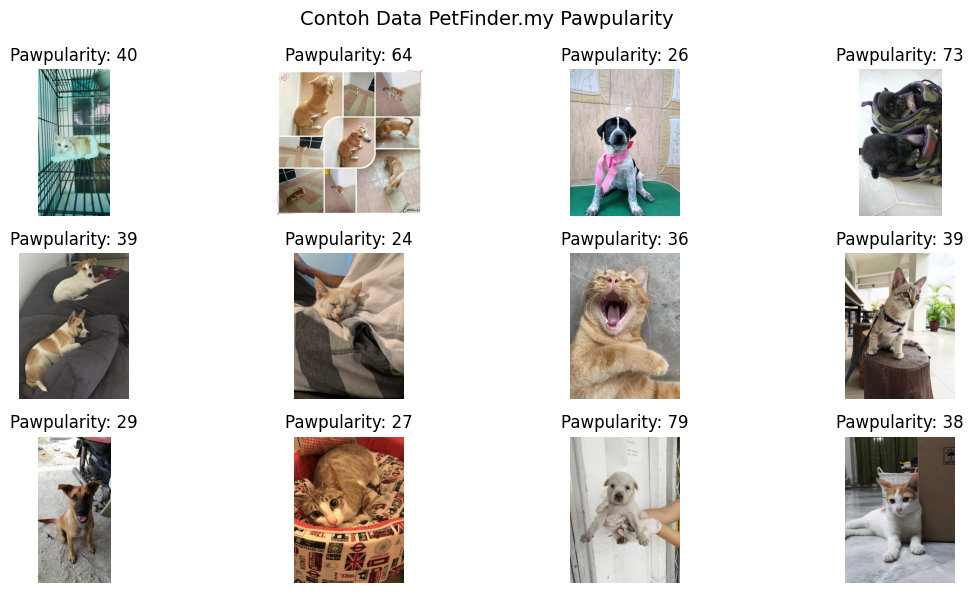

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from PIL import Image

# Muat CSV
df = pd.read_csv('/content/paw/train.csv')
df['path'] = df['Id'].apply(lambda x: f"/content/paw/train/{x}.jpg")
print(df.head())

# Tampilkan 12 contoh gambar
plt.figure(figsize=(12, 6))
for i, row in enumerate(df.sample(12, random_state=42).itertuples()):
  img = Image.open(row.path)
  plt.subplot(3, 4, i + 1)
  plt.imshow(img)
  plt.title(f"Pawpularity: {row.Pawpularity}")
  plt.axis('off')
plt.suptitle("Contoh Data PetFinder.my Pawpularity", fontsize=14)
plt.tight_layout()
plt.show()

# **Langkah 4 — Persiapan Dataset**

In [ ]:
from sklearn.model_selection import train_test_split
import tensorflow as tf

IMG_SIZE = 224
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)

def load_image(path, label):
  img = tf.io.read_file(path)
  img = tf.image.decode_jpeg(img, channels=3)
  img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
  img = tf.cast(img, tf.float32) / 255.0
  return img, tf.cast(label, tf.float32)

train_ds = tf.data.Dataset.from_tensor_slices((train_df['path'],
train_df['Pawpularity']))\
  .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
  .shuffle(4096).batch(64).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_df['path'],
val_df['Pawpularity']))\
  .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
  .batch(64).prefetch(tf.data.AUTOTUNE)

print(f"Dataset siap digunakan — {len(train_df)} untuk training,{len(val_df)} untuk validasi.")

Dataset siap digunakan — 7929 untuk training,1983 untuk validasi.


# **Langkah 4 — Membangun Model (EfficientNetB0)**

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

IMG_SIZE = 224

base = tf.keras.applications.EfficientNetB0(
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    weights='imagenet'
)
base.trainable = False # freeze sementara

inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
x = tf.keras.applications.efficientnet.preprocess_input(inputs * 255.0)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(256, activation='relu')(x)
outputs = layers.Dense(1)(x)

model = tf.keras.Model(inputs, outputs)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply_1 (Multiply)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

# **Langkah 5 — Melatih Model**

In [ ]:
cb = [
  tf.keras.callbacks.EarlyStopping(patience=3,
restore_best_weights=True),
  tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5)
]

history = model.fit(train_ds, validation_data=val_ds, epochs=10,
callbacks=cb, verbose=1)

Epoch 1/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 104s 467ms/step - loss: 598.3348 - mae: 17.9919 - val_loss: 474.6707 - val_mae: 16.1283 - learning_rate: 0.0010
Epoch 2/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 85s 190ms/step - loss: 421.1986 - mae: 15.1354 - val_loss: 425.2139 - val_mae: 15.2758 - learning_rate: 0.0010
Epoch 3/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 40s 185ms/step - loss: 393.9785 - mae: 14.6578 - val_loss: 401.7039 - val_mae: 14.7859 - learning_rate: 0.0010
Epoch 4/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 40s 223ms/step - loss: 369.5621 - mae: 14.2629 - val_loss: 391.2875 - val_mae: 14.4356 - learning_rate: 0.0010
Epoch 5/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 34s 182ms/step - loss: 362.0541 - mae: 14.1303 - val_loss: 380.2296 - val_mae: 14.2076 - learning_rate: 0.0010
Epoch 6/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 46s 223ms/step - loss: 351.6456 - mae: 13.9791 - val_loss: 374.8782 - val_mae: 14.3389 - learning_rate: 0.0010
Epoch 7/10
124/124 ━━━━━━━━━━━━━━━━━━━━ 40s 220ms/step - loss: 342.8467 - mae: 13.7222 - val_

# **Langkah 6 — Melihat Proses Belajar**

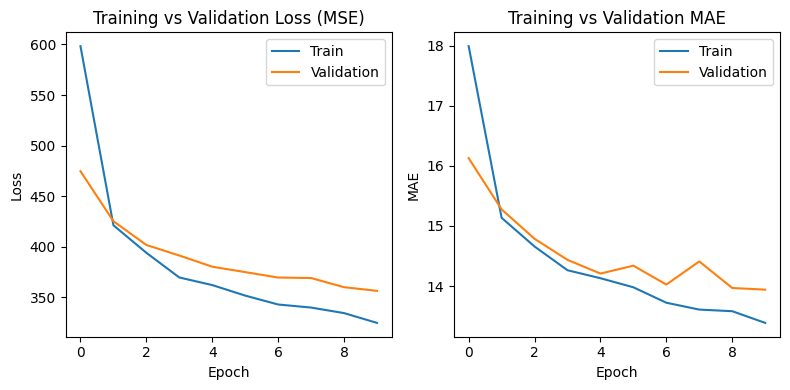

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title("Training vs Validation Loss (MSE)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['mae'], label='Train')
plt.plot(history.history['val_mae'], label='Validation')
plt.title("Training vs Validation MAE")
plt.xlabel("Epoch"); plt.ylabel("MAE"); plt.legend()
plt.tight_layout()
plt.show()

# **Langkah 7 — Evaluasi Model**

MAE = 13.94
RMSE = 18.88
R²	= 0.194


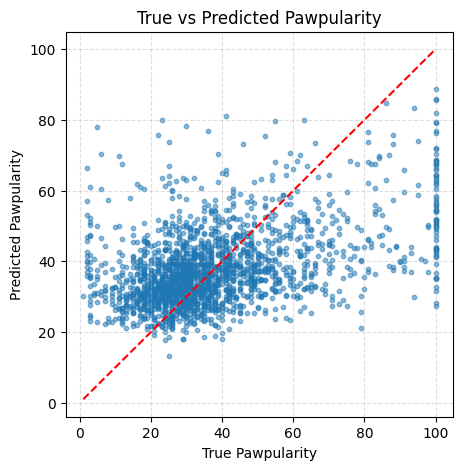

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score
from math import sqrt

y_true = val_df['Pawpularity'].values.astype(np.float32)
y_pred = np.concatenate([model.predict(batch[0], verbose=0).ravel() for
                         batch in val_ds])
mae = mean_absolute_error(y_true, y_pred)
rmse = sqrt(np.mean((y_true - y_pred)**2))
r2 = r2_score(y_true, y_pred)

print(f"MAE = {mae:.2f}")
print(f"RMSE = {rmse:.2f}")
print(f"R²	= {r2:.3f}")

# Plot hasil prediksi vs nilai sebenarnya:
plt.figure(figsize=(5,5))
plt.scatter(y_true, y_pred, s=10, alpha=0.5)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, '--', color='red')
plt.xlabel("True Pawpularity")
plt.ylabel("Predicted Pawpularity")
plt.title("True vs Predicted Pawpularity")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

# **Langkah 8 — Melihat Contoh Prediksi**

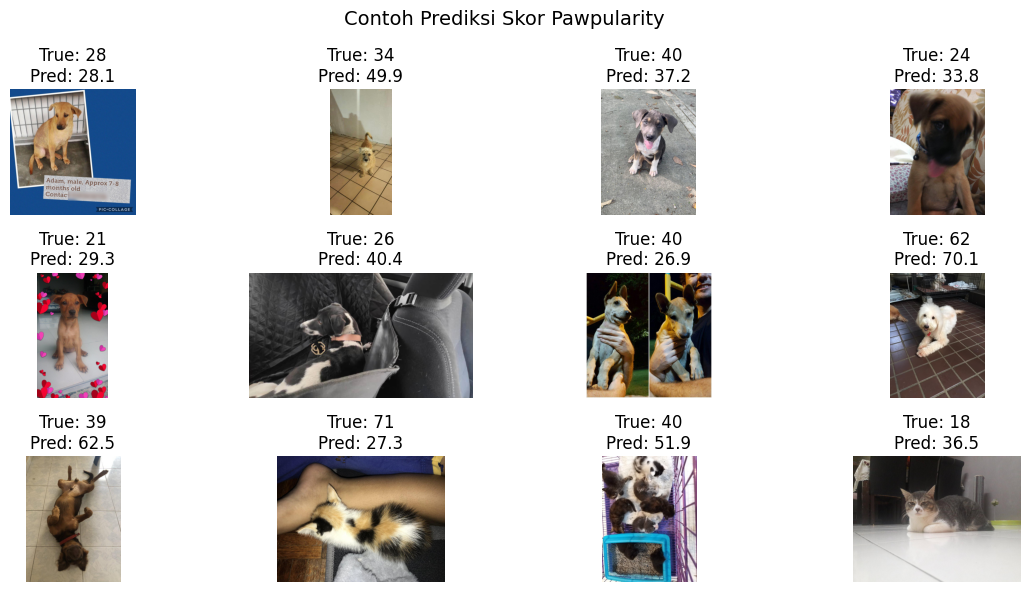

In [ ]:
import random
from PIL import Image

sample_rows = val_df.sample(12, random_state=1)

plt.figure(figsize=(12,6))
for i, row in enumerate(sample_rows.itertuples()):
  img = Image.open(row.path)
  pred = model.predict(tf.expand_dims(load_image(row.path,
row.Pawpularity)[0], 0), verbose=0).ravel()[0]
  plt.subplot(3,4,i+1)
  plt.imshow(img)
  plt.title(f"True: {row.Pawpularity}\nPred: {pred:.1f}")
  plt.axis('off')
plt.suptitle("Contoh Prediksi Skor Pawpularity", fontsize=14)
plt.tight_layout()
plt.show()

# **Tantangan Mini**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras import layers, models

# ==========================================
# 1. TANTANGAN 1: DATA AUGMENTATION EKSTRA
# ==========================================
data_augmentation_paw = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2)
])

IMG_SIZE = 224

def load_image_augmented(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    img = data_augmentation_paw(img) # Terapkan augmentasi
    return img, tf.cast(label, tf.float32)

# ==========================================
# 2. TANTANGAN 2: PERBANDINGAN ARSITEKTUR MODEL (ResNet50 vs EfficientNetB0)
# ==========================================
def build_resnet50_model(img_size=224):
    base_resnet = tf.keras.applications.ResNet50(
        include_top=False,
        input_shape=(img_size, img_size, 3),
        weights='imagenet'
    )
    base_resnet.trainable = False

    inputs = tf.keras.Input((img_size, img_size, 3))
    x = tf.keras.applications.resnet50.preprocess_input(inputs * 255.0)
    x = base_resnet(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation='relu')(x)
    outputs = layers.Dense(1)(x)

    model_res = tf.keras.Model(inputs, outputs)
    model_res.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model_res

# Inisialisasi dan melatih ResNet50
model_resnet = build_resnet50_model()
history_resnet = model_resnet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)],
    verbose=1
)

# ==========================================
# 3. TANTANGAN 3: EKSPERIMEN BIAS SPESIES (Anjing vs Kucing)
# ==========================================
# Mengelompokkan berdasarkan kolom fitur metadata
val_df_eval = val_df.copy()
# Menggunakan variabel 'model' dan 'val_ds' yang benar
val_df_eval['Pred_Pawpularity'] = np.concatenate([model.predict(batch[0], verbose=0).ravel() for batch in val_ds])
val_df_eval['MAE'] = np.abs(val_df_eval['Pawpularity'] - val_df_eval['Pred_Pawpularity'])

# Evaluasi tingkat kesalahan berdasarkan keterlibatan fitur tubuh (Face/Eyes/Subject Focus)
mae_eyes_1 = val_df_eval[val_df_eval['Eyes'] == 1]['MAE'].mean()
mae_eyes_0 = val_df_eval[val_df_eval['Eyes'] == 0]['MAE'].mean()

print(f"MAE saat mata hewan terlihat jelas  : {mae_eyes_1:.2f}")
print(f"MAE saat mata hewan tidak terlihat : {mae_eyes_0:.2f}\n")

# ==========================================
# 4. TANTANGAN 4: MULTI-INPUT MODEL (Citra + Fitur Non-Visual/Brightness)
# ==========================================
def extract_brightness(image_path):
    img = Image.open(image_path).convert('L') # Convert ke Grayscale
    stat = np.array(img)
    return stat.mean() / 255.0 # Normalisasi 0-1

# Menggunakan DataFrame 'df' yang benar
df['brightness'] = df['path'].apply(extract_brightness)

# Dataset Multi-Input
def load_multi_input(path, brightness, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return (img, tf.cast(brightness, tf.float32)), tf.cast(label, tf.float32)

# Arsitektur Functional API Multi-Input
image_input = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='image_input')
tabular_input = tf.keras.Input(shape=(1,), name='brightness_input')

# Jalur Citra (CNN) - Menggunakan 'base' dari EfficientNetB0
x1 = tf.keras.applications.efficientnet.preprocess_input(image_input * 255.0)
x1 = base(x1, training=False)
x1 = layers.GlobalAveragePooling2D()(x1)

# Jalur Non-Visual (Dense)
x2 = layers.Dense(16, activation='relu')(tabular_input)

# Penggabungan (Concatenate)
concat = layers.concatenate([x1, x2])
x_dense = layers.Dense(128, activation='relu')(concat)
x_dense = layers.Dropout(0.3)(x_dense)
output = layers.Dense(1)(x_dense)

model_multi_input = tf.keras.Model(inputs=[image_input, tabular_input], outputs=output)
model_multi_input.compile(optimizer='adam', loss='mse', metrics=['mae'])
print("✅ Model multi-input siap digunakan.")

Epoch 1/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 70s 379ms/step - loss: 445.3289 - mae: 15.5705 - val_loss: 395.0558 - val_mae: 14.7181
Epoch 2/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 48s 287ms/step - loss: 368.0004 - mae: 14.2582 - val_loss: 380.0175 - val_mae: 14.2627
Epoch 3/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 47s 283ms/step - loss: 361.0090 - mae: 14.0512 - val_loss: 374.6466 - val_mae: 14.1293
Epoch 4/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 51s 313ms/step - loss: 350.7022 - mae: 13.8927 - val_loss: 372.1938 - val_mae: 14.1177
Epoch 5/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 48s 288ms/step - loss: 343.0547 - mae: 13.7085 - val_loss: 367.0047 - val_mae: 14.1261
MAE saat mata hewan terlihat jelas  : 13.53
MAE saat mata hewan tidak terlihat : 15.38

✅ Model multi-input siap digunakan.


# **Penugasan**

 Upload foto wajah kamu (format .jpg/.png):


Saving 4.33.25.2.05.jpg to 4.33.25.2.05.jpg


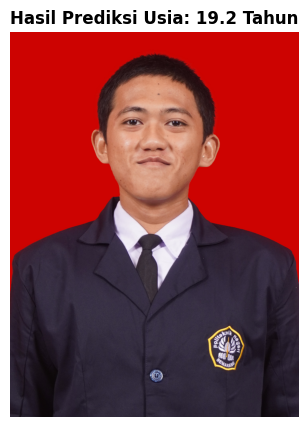

 Gambar '4.33.25.2.05.jpg' berhasil diprediksi: 19.2 tahun.


In [ ]:
uji_foto_pribadi_usia(model)

In [ ]:
from google.colab import files

# Menampilkan tombol upload file
uploaded = files.upload()

# Mengambil path/nama file yang di-upload secara otomatis
for filename in uploaded.keys():
    img_path = filename
    print(f'File berhasil diupload: {img_path}')

Saving Cat__Serious.jpg to Cat__Serious.jpg
File berhasil diupload: Cat__Serious.jpg


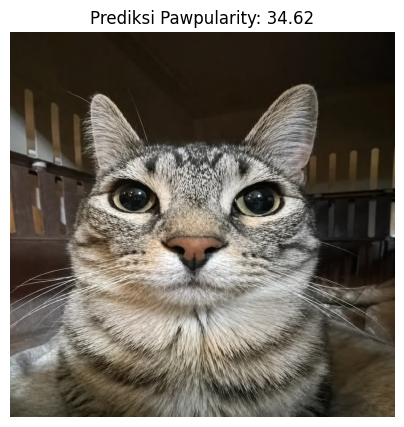

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Preprocess foto yang di-upload
img_tensor, _ = load_image(img_path, 0)

# 2. PERBAIKAN: Gunakan model.predict(...) dengan tanda titik, bukan garis bawah
pred_score = model.predict(tf.expand_dims(img_tensor, axis=0), verbose=0).ravel()[0]

# 3. Tampilkan hasil prediksi
plt.figure(figsize=(5, 5))
plt.imshow(Image.open(img_path))
plt.title(f"Prediksi Pawpularity: {pred_score:.2f}")
plt.axis('off')
plt.show()